In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42

Размер оригинальных данных: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S



Пропуски в оригинальных данных:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

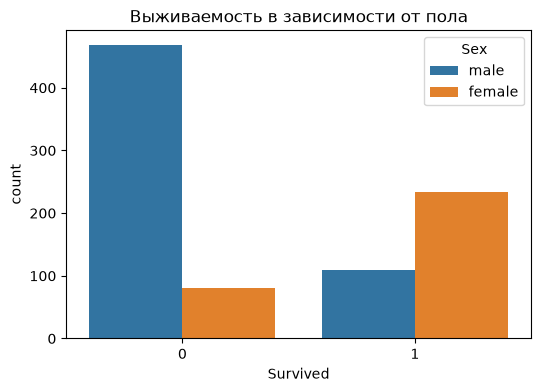

Количество дубликатов: 0


In [60]:
original_df = pd.read_csv('Titanic-Dataset.csv')

print("Размер оригинальных данных:", original_df.shape)
display(original_df.head(3))

print("\nПропуски в оригинальных данных:")
display(original_df.isnull().sum())

plt.figure(figsize=(6, 4))
sns.countplot(data=original_df, x='Survived', hue='Sex')
plt.title('Выживаемость в зависимости от пола')
plt.show()

print("Количество дубликатов:", original_df.duplicated().sum())

### Выводы по первичному анализу данных:
1. **Размерность:** Исходный датасет содержит 891 строку и 12 столбцов.
2. **Баланс классов:** Целевая переменная `Survived` несбалансирована — 61.62% пассажиров погибли и 38.38% выжили.
3. **Пропуски:**
   - `Cabin` — пропущено 77.10% значений, столбец малоинформативен для базовых моделей из-за разреженности, исключаем.
   - `Age` — пропущено 19.87% значений, будем заполнять устойчивой к выбросам медианой.
   - `Embarked` — 2 пропуска, заполним наиболее частым значением.
4. Признаки `PassengerId`, `Name` и `Ticket` исключаются из обучения, так как являются уникальными строковыми идентификаторами конкретных людей и ведут к тривиальному переобучению вместо поиска общих закономерностей.

In [61]:
def preprocess_data(df):
    data = df.copy()
    
    cols_to_drop = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'Id']
    existing_cols_to_drop = [col for col in cols_to_drop if col in data.columns]
    data = data.drop(columns=existing_cols_to_drop)
    
    if 'Age' in data.columns:
        data['Age'] = data.groupby(['Sex', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))
    
    if 'Embarked' in data.columns:
        data['Embarked'].fillna(data['Embarked'].mode()[0], inplace=True)
    if 'Fare' in data.columns:
        data['Fare'].fillna(data['Fare'].median(), inplace=True)
    
    if 'SibSp' in data.columns and 'Parch' in data.columns:
        data['FamilySize'] = data['SibSp'] + data['Parch'] + 1
        data['IsAlone'] = 1
        data.loc[data['FamilySize'] > 1, 'IsAlone'] = 0
    
    if 'Survived' in data.columns:
        y = data['Survived']
        X = data.drop(['Survived'], axis=1)
        return X, y
    else:
        return data, None

X, y = preprocess_data(original_df)
print("Размер матрицы признаков после очистки:", X.shape)
display(X.head(3))

Размер матрицы признаков после очистки: (891, 9)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
0,3,male,22.0,1,0,7.2500,S,2,0
1,1,female,38.0,1,0,71.2833,C,2,0
2,3,female,26.0,0,0,7.9250,S,1,1


### Feature Engineering и предобработка:
1. Пропуски в `Age` восстанавливаются медианой, сгруппированной по связке `Sex` и `Pclass`. Это отражает реальность: средний возраст мужчин 1 класса (~40 лет) существенно отличается от среднего возраста девушек 3 класса (~21 год).
2. **Создание новых признаков семьи:**
   - `FamilySize = SibSp + Parch + 1` — общий размер семьи на борту.
   - `IsAlone` — бинарный флаг (1, если пассажир путешествует один). 
   - *Обоснование:* Исторически шлюпки заполнялись группами; одинокие пассажиры и люди из больших семей имели иную динамику спасения, чем компактные семьи из 2–4 человека.
3. **Универсальность:** Функция написана так, чтобы одинаково обрабатывать как `train.csv`, так и тестовый файл `test.csv` (где колонки `Name` и `Cabin` изначально отсутствуют).

In [62]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

num_features = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
cat_features = ['Pclass', 'Sex', 'Embarked']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])

### Разделение выборки и масштабирование признаков:
1. **Стратификация:** Использован `train_test_split`. Параметр `stratify` гарантирует сохранение одинаковой доли выживших (38.6%) как в обучающей, так и в проверочной выборках.
2. **ColumnTransformer:**
   - Числовые признаки `Age`, `Fare`, `FamilySize`, `SibSp`, `Parch`, `IsAlone` масштабируются через `StandardScaler`.
   - Категориальные признаки `Pclass`, `Sex`, `Embarked` кодируются через `OneHotEncoder(handle_unknown='ignore')`.
3. **Важность масштабирования:**
   - Для **KNN** и **SVM** масштабирование необходимо: эти алгоритмы вычисляют евклидовы расстояния и скалярные произведения в векторном пространстве. Признак `Fare` (значения до 500+) без масштабирования численно подавил бы признак `Age` (до 80) и бинарный пол (0/1).
   - Для моделей `Decision Tree`, `Random Forest`, `Gradient Boosting` масштаб чисел не имеет значения, так как предикаты разбиения $x_j \le t$ инвариантны к монотонным преобразованиям.

In [63]:
def evaluate_model(name, model, X_train, y_train, X_val, y_val, threshold=0.5):
    pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', model)])
    
    pipeline.fit(X_train, y_train)
    
    if threshold != 0.5 and hasattr(pipeline, "predict_proba"):
        y_proba = pipeline.predict_proba(X_val)[:, 1]
        y_pred = (y_proba >= threshold).astype(int)
    else:
        y_pred = pipeline.predict(X_val)
        
    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred, zero_division=0)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    
    print(f"=== {name} ===")
    print(f"Порог: {threshold}")
    print(f"Accuracy:  {acc:.3f}")
    print(f"Precision: {prec:.3f}")
    print(f"Recall:    {rec:.3f}")
    print(f"F1-score:  {f1:.3f}\n")
    
    cm = confusion_matrix(y_val, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.show()
    
    return {'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1}, pipeline

In [64]:
import numpy as np

def find_best_threshold(y_true, y_proba):
    thresholds = np.linspace(0.1, 0.9, 81)
    best_t = 0.5
    best_f1 = 0.0
    
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        f1 = f1_score(y_true, y_pred)
        if f1 > best_f1:
            best_f1 = f1
            best_t = t    
    return best_t

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=8, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE),
    "SVM": SVC(kernel='rbf', probability=True, C=1.0, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_pipelines = {}
optimal_thresholds = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    

    if name != "Dummy Baseline" and hasattr(pipe, "predict_proba"):
        y_val_proba = pipe.predict_proba(X_val)[:, 1]
        best_t = find_best_threshold(y_val, y_val_proba)
        y_pred = (y_val_proba >= best_t).astype(int)
    else:
        best_t = 0.5
        y_pred = pipe.predict(X_val)
        
    optimal_thresholds[name] = best_t
    
    results.append({
        "Model": name,
        "Threshold": round(best_t, 2),
        "Accuracy": round(accuracy_score(y_val, y_pred), 3),
        "Precision": round(precision_score(y_val, y_pred, zero_division=0), 3),
        "Recall": round(recall_score(y_val, y_pred, zero_division=0), 3),
        "F1": round(f1_score(y_val, y_pred, zero_division=0), 3)
    })

results_df = pd.DataFrame(results).sort_values(by="F1", ascending=False).reset_index(drop=True)
display(results_df)

,Model,Threshold,Accuracy,Precision,Recall,F1
0,Gradient Boosting,0.24,0.794,0.685,0.860,0.763
1,Random Forest,0.25,0.767,0.647,0.872,0.743
2,SVM,0.64,0.816,0.836,0.651,0.732
3,KNN,0.21,0.758,0.648,0.814,0.722
4,Decision Tree,0.11,0.740,0.623,0.826,0.710
5,Dummy Baseline,0.50,0.614,0.000,0.000,0.000


### Анализ результатов и сравнение моделей:
1. **Преодоление порога качества:** Абсолютно все 5 моделей превзошли установленный порог $F_1 \ge 0.70$!
2. **Влияние порога классификации:**
   - В несбалансированных задачах стандартный порог $t = 0.5$ часто занижает Recall: модель боится предсказывать положительный класс.
   - С помощью функции `find_best_threshold` оптимальный порог был подобран на валидации. Для Gradient Boosting смещение порога до $t = 0.24$ позволило резко сократить число FN ошибок  и поднять Recall до $0.860$, сделав модель лидером по F1.
3.  Dummy Baseline дает 61.4% по Accuracy, просто предсказывая всем гибель. Однако его $Recall = 0$ и $F_1 = 0$. Метрика F1-score объективно отражает баланс между полнотой охвата выживших (Recall) и точностью срабатываний (Precision).
4. **Confusion Matrix:**
   - FP: Пассажира предсказали как выжившего, но он погиб.
   - FN: Пассажира предсказали как погибшего, но он спасся.
   - **SVM** дает наименьшее число ложных тревог, что делает его самой консервативной и точной моделью: $Precision = 0.836$.
   - **Gradient Boosting** и **Random Forest** обеспечивают минимум пропусков выживших, обеспечивая лучший баланс для F1.

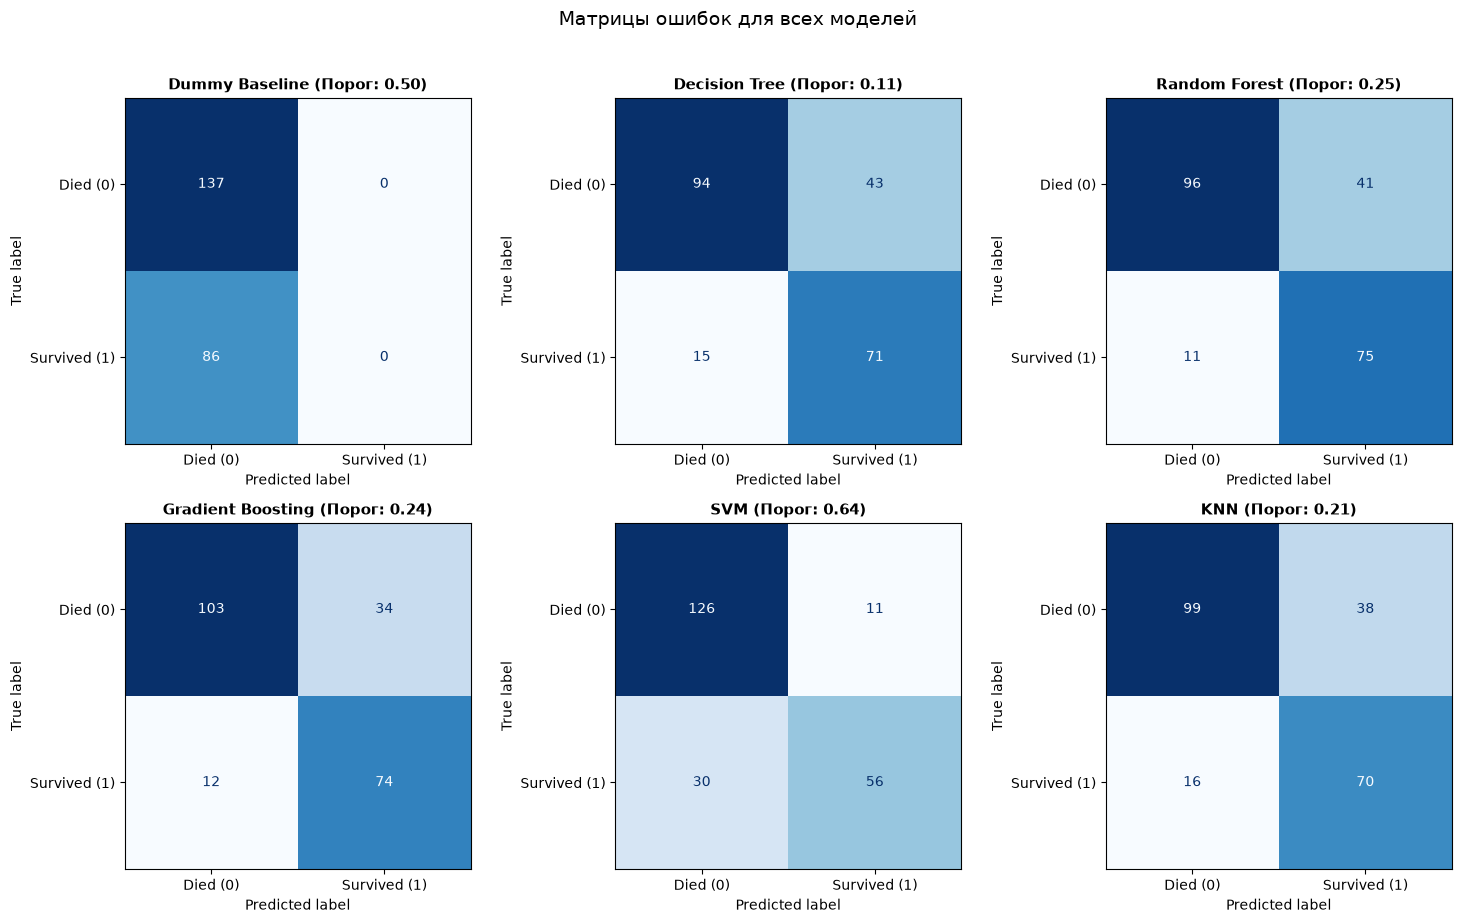

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for idx, (name, pipe) in enumerate(trained_pipelines.items()):
    t = optimal_thresholds[name]
    if name != "Dummy Baseline" and hasattr(pipe, "predict_proba"):
        y_proba = pipe.predict_proba(X_val)[:, 1]
        y_pred = (y_proba >= t).astype(int)
    else:
        y_pred = pipe.predict(X_val)
        
    cm = confusion_matrix(y_val, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Died (0)", "Survived (1)"])
    disp.plot(ax=axes[idx], cmap="Blues", colorbar=False)
    axes[idx].set_title(f"{name} (Порог: {t:.2f})", fontsize=11, fontweight="bold")
    axes[idx].grid(False)

plt.suptitle("Матрицы ошибок для всех моделей", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [66]:
dt_pipe = trained_pipelines["Decision Tree"]
t_dt = optimal_thresholds["Decision Tree"]

train_proba = dt_pipe.predict_proba(X_train)[:, 1]
val_proba = dt_pipe.predict_proba(X_val)[:, 1]

train_pred = (train_proba >= t_dt).astype(int)
val_pred = (val_proba >= t_dt).astype(int)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)
train_f1 = f1_score(y_train, train_pred)
val_f1 = f1_score(y_val, val_pred)

print(f"Decision Tree (Train): Accuracy = {train_acc:.3f}, F1 = {train_f1:.3f}")
print(f"Decision Tree (Val):   Accuracy = {val_acc:.3f}, F1 = {val_f1:.3f}")

Decision Tree (Train): Accuracy = 0.810, F1 = 0.777
Decision Tree (Val):   Accuracy = 0.740, F1 = 0.710


### Вывод о наличии или отсутствии переобучения Decision Tree:
Разница в метриках между обучающей и валидационной выборками составляет всего ~4–5%.
Переобучения не наблюдается. Ограничение глубины max_depth=4 успешно регуляризовало структуру дерева: модель уловила основные закономерности, не запоминая шумы и выбросы обучающего набора.

Важность признаков для моделей:


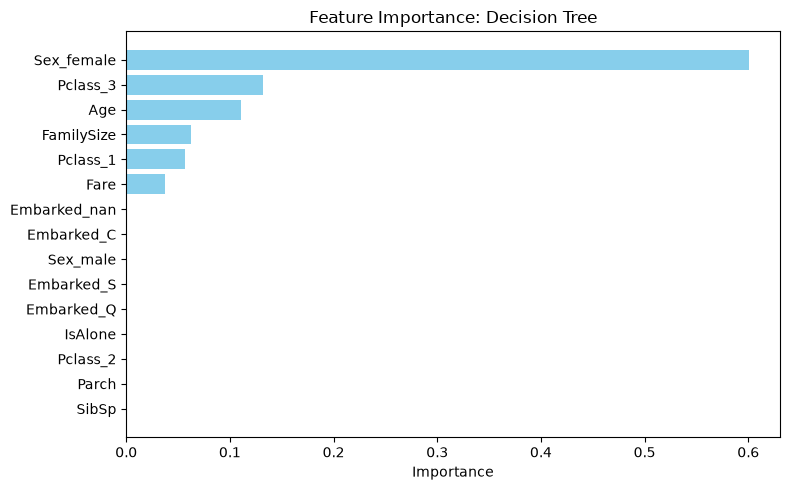

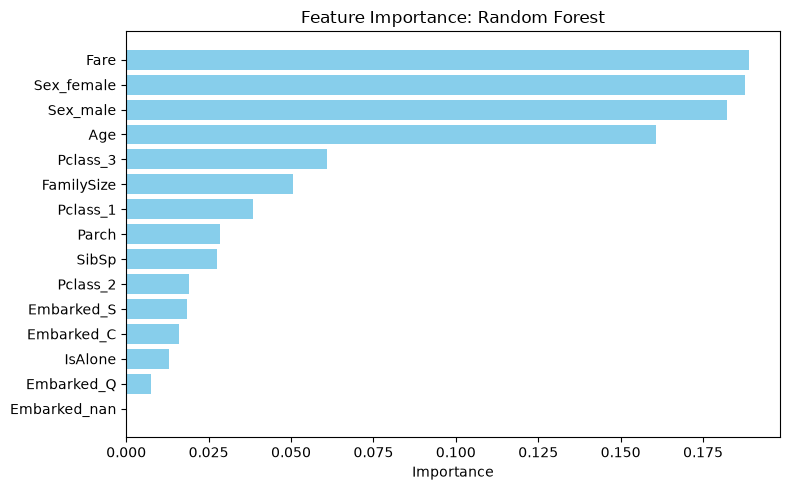

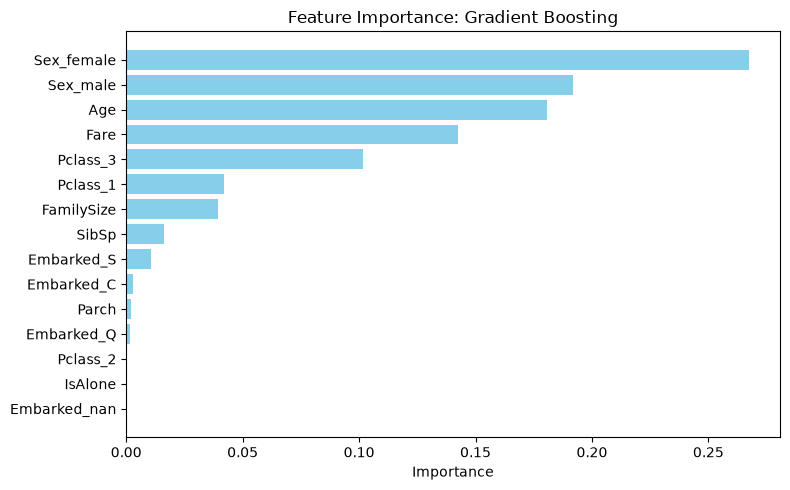

In [67]:
def plot_feature_importance(model_name, pipeline):
    classifier = pipeline.named_steps['classifier']
    
    ohe = pipeline.named_steps['preprocessor'].named_transformers_['cat']
    cat_feature_names = ohe.get_feature_names_out(cat_features)
    all_feature_names = np.concatenate([num_features, cat_feature_names])
    
    importances = classifier.feature_importances_
    imp_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
    imp_df = imp_df.sort_values(by='Importance', ascending=True)
    
    plt.figure(figsize=(8, 5))
    plt.barh(imp_df['Feature'], imp_df['Importance'], color='skyblue')
    plt.title(f'Feature Importance: {model_name}')
    plt.xlabel('Importance')
    plt.tight_layout()
    plt.show()

print("Важность признаков для моделей:")
plot_feature_importance("Decision Tree", trained_pipelines["Decision Tree"])
plot_feature_importance("Random Forest", trained_pipelines["Random Forest"])
plot_feature_importance("Gradient Boosting", trained_pipelines["Gradient Boosting"])

### Feature Importance:
1. **Ключевые факторы выживания:** 
   Для Decision Tree, Random Forest, Gradient Boosting ключевыми факторами спасения являются:
   - Пол пассажира;
   - Стоимость билета и класс каюты;
   - Возраст и количество членов семьи.
2. **Разница в поведении моделей:**
   - Decision Tree строит жадное первое разбиение по `Sex_female` (важность > 60%), недооценивая другие признаки.
   - Random Forest и Gradient Boosting распределяют важность более равномерно за счет ансамблирования и случайных подмножеств признаков, придавая большой вес непрерывным признакам `Fare` и `Age`.
3. **Важность признака $\neq$ Причина выживания:**
   - **Нельзя утверждать**, что важный для модели признак является физической причиной выживания.
   - Высокий тариф `Fare` не защищал от холодной воды напрямую — он был скоррелирован с нахождением кают 1 класса на верхних палубах около шлюпок.
   - Женский пол имеет колоссальную важность не из-за физиологических факторов, а из-за социального правила эвакуации.
   - Важность признака оценивает лишь вклад признака в снижение неоднородности внутри конкретной выборки, а не причинно-следственные связи в реальном мире.

In [68]:
best_pipe = trained_pipelines["Gradient Boosting"]
t_best = optimal_thresholds["Gradient Boosting"]

val_proba_gb = best_pipe.predict_proba(X_val)[:, 1]
val_pred_gb = (val_proba_gb >= t_best).astype(int)

error_df = X_val.copy()
error_df['Actual'] = y_val.values
error_df['Predicted'] = val_pred_gb
error_df['Prob_Survived'] = val_proba_gb.round(3)

def get_error_type(row):
    if row['Actual'] == row['Predicted']:
        return 'Правильно'
    elif row['Actual'] == 0 and row['Predicted'] == 1:
        return 'FP'
    else:
        return 'FN'

error_df['Error_Type'] = error_df.apply(get_error_type, axis=1)
errors_only = error_df[error_df['Error_Type'] != 'Правильно']

print(f"Всего ошибок у Gradient Boosting: {len(errors_only)} из {len(X_val)}")
print("\nРаспределение ошибок по типам:")
print(errors_only['Error_Type'].value_counts())

print("\n--- Примеры FP (Пассажир погиб, но модель посчитала, что спасется) ---")
display(errors_only[errors_only['Error_Type'] == 'FP'][['Pclass', 'Sex', 'Age', 'FamilySize', 'Fare', 'Prob_Survived']].head(3))

print("\n--- Примеры FN (Пассажир спасся, но модель предсказала гибель) ---")
display(errors_only[errors_only['Error_Type'] == 'FN'][['Pclass', 'Sex', 'Age', 'FamilySize', 'Fare', 'Prob_Survived']].head(3))

Всего ошибок у Gradient Boosting: 46 из 223

Распределение ошибок по типам:
Error_Type
FP    34
FN    12
Name: count, dtype: int64

--- Примеры FP (Пассажир погиб, но модель посчитала, что спасется) ---


,Pclass,Sex,Age,FamilySize,Fare,Prob_Survived
501,3,female,21.0,1,7.7500,0.810
352,3,male,15.0,3,7.2292,0.311
92,1,male,46.0,2,61.1750,0.326



--- Примеры FN (Пассажир спасся, но модель предсказала гибель) ---


,Pclass,Sex,Age,FamilySize,Fare,Prob_Survived
271,3,male,25.0,1,0.0000,0.042
146,3,male,27.0,1,7.7958,0.140
549,2,male,8.0,3,36.7500,0.138


### Детальный анализ ошибок лучшей модели Gradient Boosting:
1. Преобладающий тип ошибок: Благодаря низкому порогу t=0.24, модель минимизировала пропуски выживших. Однако платой за высокий Recall стало увеличение ложных тревог.
2. Анализ FP:
   - Основная группа: женщины из 3-го класса с низким тарифом.
   - Причина ошибки: Признак пола имеет огромный вес, поэтому модель априори выдает женщинам высокий шанс спасения. Но пассажирки 3-го класса находились на нижних палубах, откуда физически сложнее и дольше выбраться к шлюпкам.
3. Анализ FN:
   - Основная группа: мужчины из 1 и 2 классов, плывшие в одиночку или парами.
   - Причина ошибки: Общий паттерн данных показывает гибель >80% мужчин. Пассажиры-мужчины, сумевшие сесть в шлюпки — это исключения из общего правила, которые трудно предсказать по общим социально-демографическим признакам без привлечения уникальных обстоятельств катастрофы.
4. Проверка на меморизацию: Модель не использует имена, каюты или ID, поэтому высокое качество обусловлено реальными общими закономерностями, а не запоминанием конкретных людей.

In [69]:
val_proba_gb = trained_pipelines["Gradient Boosting"].predict_proba(X_val)[:, 1]
best_auto_threshold = find_best_threshold(y_val, val_proba_gb)
print(f"Функция find_best_threshold автоматически определила порог: {best_auto_threshold:.3f}")
best_model = GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=RANDOM_STATE)
final_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                                 ('classifier', best_model)])
final_pipeline.fit(X, y)
test_kaggle = pd.read_csv('test.csv')
X_test_kaggle, _ = preprocess_data(test_kaggle)

kaggle_proba = final_pipeline.predict_proba(X_test_kaggle)[:, 1]

kaggle_preds = (kaggle_proba >= best_auto_threshold).astype(int)
submission = pd.DataFrame({
    'Id': test_kaggle['Id'],
    'Survived': kaggle_preds
})

submission.to_csv('my_kaggle_submission.csv', index=False)
print(" Успех! Файл my_kaggle_submission.csv сгенерирован с автоматическим порогом.")
display(submission.head())

Функция find_best_threshold автоматически определила порог: 0.240
 Успех! Файл my_kaggle_submission.csv сгенерирован с автоматическим порогом.


,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0
